.. index:: Solvers; Sicpy (Uzawa Saddle Point)

.. index::
   triple: Equations; Stokes; Saddle-Point;

# (Quasi) Stokes equations (Scipy based PCG scheme for Schur's complement)

## Schur's complement

The Quasi-Stokes equations in weak form (neglecting all boundary
conditions) read as

\begin{align*}
\int_\Omega \rho\,u\cdot v + \sigma(u,\,p):\varepsilon(v)\,\mathrm{d}x & = \int_\Omega f\,v,\,\mathrm{d}x \\
\int_\Omega \nabla\cdot u\,q\,\mathrm{d}x &= 0.
\end{align*}

on some given domain, where $u,\,v\in X$, $p,\,q\in Q$ with $X$ and
$Q$ appropriately chosen function spaces, $\sigma$, $\epsilon$
defined as explained in the Navier-Stokes intro slides.

These equation can paraphrased as operator equations of the form

\begin{align*}
A\,u + B\,p = F,\\
B^\ast u = 0.
\end{align*}

with a self-adjoint (spd) operator $A:X \rightarrow X^\ast$, the
"gradient operator" $B:Q\rightarrow X^\ast$ and its adjoint, the
"divergence operator" $B^\ast:X\rightarrow Q^\ast$ and "right hand
side" $F\in X^\ast$. We now "virtually" solve the first equation for $u$
and substitute the result into the second equation:

\begin{align*}
u = A^{-1}\,(F - B\,p),\\
- B^\ast A^{-1}\,(F - B\,p) = 0.
\end{align*}

This means, the pressure $p$ is the unique solution of the equation

$$
\hat T\,p = (B^\ast\,A^{-1}\,B)\,p = B^\ast\,A^{-1}\,F.
$$

The velocity can then be computed from $p$ using the first
euqation. The operator $\hat T=B^\ast\,A^{-1}\,B$ is the *Schur's
complement operator* for this saddle-point problem.

As $A$ is symmetric positive definite it is clear that $\hat T$ is also
symmetric. It is also positive definite from other reasoning. Hence
it is possible to apply the PCG-method to Schur's complement
$\hat T$. This is the topic of this assignment.

## Domain and Range of Schur's complement

$\hat T$ as defined above is in principle an operator
$\hat T:Q \rightarrow Q^\ast$ as $B^\ast:X\rightarrow Q^\ast$. It holds that
it is spg w.r.t. the componentwise scalar product of the
DOF-vectors. However, we want to implement our PCG-method over the
pressure space $Q$ equipped with its standard $L^2$ scalar
product. In order to do so we need in addition to the definition of
$\hat T$ above one additional $L^2$-projection which maps the range
of $\hat T:Q\rightarrow Q^\ast$ back to $Q$. So the operator that we
use in the PCG-method which is to be implemented below is defined by

$$
p\in Q:(T\,p,\,q)_Q = \langle B^\ast\,A^{-1}\,B\,p,\,q\rangle,\text{ for all }q\in Q.
$$

## Preconditioner

From the *strong* form of the Quasi-Stokes equations it is possible
to derive a precoditioner for Schur's complement, with a lot of
"handwaving" the operator $A$ aplied to a velocity $u$ is
"something" like $\rho\,u - \mu\,\nabla\cdot\nabla u$, while $B$
corresponds to the gradient $\nabla$ of a pressure function and
$B^\ast$ corresponds to the divergence of a velocity function. In
a very vague sense we have for given $q\in Q^\ast$:

\begin{align*}
\hat T^{-1}\,q &= (B^\ast\,A^{-1}\,B)^{-1}\,q\\
&= B^{-1}\,A\,B^{-\ast}\,q\\
&= \nabla^{-1}(\rho\dots - \mu\,\nabla\cdot\nabla\dots)\,(\nabla\cdot)^{-1}\,q\\
&= \rho\,(\nabla\cdot\nabla)^{-1}\,q - \mu\,q.
\end{align*}

Mathematically, above line is horribly broken, however one can make
sense of it in terms of suitably chosen pseudo-inverses. If we
accept it, then a suitable preconditioner for $T$ is given by ($r\in Q$)

\begin{align*}
C^{-1}\,r &= \mu\,r + \rho\,\phi_r,
\end{align*}

where $\phi_r$ is the solution of Poisson's problem (in the pressure space)

\begin{align*}
-\Delta\,\phi_r &= r \text{ in }\Omega,\\
\partial_n\phi_r & =0 \text{ on }\partial\Omega
\end{align*}

where we assume no-slip boundary condition on the entire boundary. If
instead we impose stress-boundary conditions on parts of the
boundary then on those parts the boundary condition for this
subproblem has to be replaced by a homogeneous Robin boundary
condition with a penalty proportioanl to the inverse of the
mesh-size.

## Implementation Notes

- $T$ contains the inverse of $A$, so it is not feasible to assemble
  $T$. Instead, we have to exploit the fact that the PCG-method only
  uses $T$ to compute matrix-vector products. So for $p\in\,Q$ given
  in order to compute $r:=T\,p$ we perform the following steps:

  - $b:=B\,p$
  - solve $A\,x = b$ for $x$
  - $r^\ast:=B^\ast\,x$
  - solve $M_Q\,r = r^\ast$ for $r$ where $M_Q$ denotes the mass matrix in $Q$

- in the PCG-method we have to evaluate $T\,d^m$ (see pcg-slides)
  several times which implies we have to solve an equation with
  system matrix $A$ several times. Of course, we model $A$ by a
  suitable UFL-form and Dune-Fem scheme, but if we just call
  `scheme.solve(...)` then this will each time assemble $A$ and then
  solve. We can avoid the repeated assembling of always the same
  matrix by using the `linear(...)` method of the scheme and then
  solve with that pre-assembled matrix.

- Likewise, the matrices for $B$ and $B^\ast$ can be assembled
  outside of the PCG-method.

- In order to use preassembled operators in the context of Dirichlet
  boundary conditions it is necessary to use the method
  `OPERATOR.setConstraints(...)`. This can be found on the slides of
  the talk about solvers. Please note in the setup for the
  PCG-method the inhomogeneous boundary values for the velocity $u$

- Our solution of this assignment uses `scipy.sparse` and
  `numpy`. However, this is not strictly required.

- It would be a nice extencsion to implement this method in the
  context of domain decomposition. This would require to add
  communication statements at the proper places and rather use the
  linear algebra methods (like `scalarProductDofs(...)`) from Dune
  than from scipy.


In [1]:
from matplotlib import pyplot
import numpy
from scipy.sparse import bmat, linalg
from dune.grid import cartesianDomain
from dune.alugrid import aluCubeGrid
from dune.fem.space import lagrange, dgonb
from dune.fem.operator import galerkin as galerkinOperator
from ufl import SpatialCoordinate, CellVolume, TrialFunction, TestFunction,\
                inner, dot, div, grad, dx, as_vector, transpose, Identity
from dune.ufl import Constant, DirichletBC
import dune.fem

rhoValue = 1
muValue = 0.1
order = 2

# feel free to replace this with you favourite FE-mesh
grid = aluCubeGrid(constructor=cartesianDomain([0,0],[3,1],[30,10]))
spcU = lagrange(grid, dimRange=grid.dimension, order=order, storage="numpy")
spcP = lagrange(grid, order=order-1, storage="numpy")

x     = SpatialCoordinate(spcU)
rho    = Constant(rhoValue, "rho")
mu    = Constant(muValue, "mu")
u     = TrialFunction(spcU)
v     = TestFunction(spcU)
p     = TrialFunction(spcP)
q     = TestFunction(spcP)

exact_u     = as_vector( [x[1] * (1.-x[1]), 0] )
exact_p     = (-2*x[0] + 2)*rho
f           = as_vector( [0,]*grid.dimension )
f          += mu*exact_u

## Task: define the models and operators
I.e. define the UFL form and generate a couple of
`galerkinOperator`s for all needed parts.

In [2]:
mainModel   = (rho*dot(u,v) + mu*inner(grad(u)+grad(u).T, grad(v)) - dot(f,v)) * dx
gradModel   = -inner( p*Identity(grid.dimension), grad(v) ) * dx
divModel    = -div(u)*q * dx
massModel   = p*q * dx
preconModel = inner(grad(p),grad(q)) * dx

mainOp      = galerkinOperator( (mainModel, DirichletBC(spcU,exact_u)), spcU)
gradOp      = galerkinOperator( gradModel, spcP,spcU)
divOp       = galerkinOperator( divModel, spcU,spcP)
massOp      = galerkinOperator( massModel, spcP)

## Task: assemble the matrices

In [3]:

A = mainOp.linear()
A = A.as_numpy
def Ainv(rhs,target): target[:] = linalg.spsolve(A,rhs)
G = gradOp.linear()
G = G.as_numpy
D = divOp.linear()
D = D.as_numpy
M = massOp.linear()
M = M.as_numpy
def Minv(rhs,target): target[:] = linalg.spsolve(M,rhs)

if mainOp.model.rho > 0: # same as rho.value>0
    preconOp    = galerkinOperator( preconModel, spcP )
    P = preconOp.linear().as_numpy
    def Pinv(rhs,target): target[:] = linalg.spsolve(P,rhs)

# discrete functions
velocity = spcU.interpolate(spcU.dimRange*[0], name="velocity")
pressure = spcP.interpolate(0, name="pressure")
sol_u  = velocity.as_numpy
sol_p  = pressure.as_numpy

# aux. function
rhsVelo  = velocity.copy()
rhsPress = pressure.copy()
rhs_u  = rhsVelo.as_numpy
rhs_p  = rhsPress.as_numpy
r      = numpy.copy(rhs_p)
d      = numpy.copy(rhs_p)
precon = numpy.copy(rhs_p)
xi     = numpy.copy(rhs_u)

## Task: compute the "right hand side" for Schur's complement operator

In [4]:
# right hand side for Schur complement problem
mainOp(velocity,rhsVelo)
rhs_u *= -1
xi[:] = G*sol_p
rhs_u -= xi
mainOp.setConstraints(rhsVelo)

## Task: implement the initialization step of the PCG iteration

In [5]:
Ainv(rhs_u[:], sol_u[:])
rhs_p[:] = D*sol_u
Minv(rhs_p, r)
if mainOp.model.rho > 0:
    precon.fill(0)
    Pinv(rhs_p, precon)
    r *= mainOp.model.mu
    r += mainOp.model.rho*precon
d[:] = r[:]
delta = numpy.dot(r,rhs_p)

# The following is "just" the PCG algorithm applied to Schur's
# complement. One may also think of it as Uzava optimized for
# symmetric operators ...

## Task: implement the PCG iteration

In [6]:
for m in range(100):
    xi.fill(0)
    rhs_u[:] = G*d
    mainOp.setConstraints([0,]*grid.dimension, rhsVelo)
    Ainv(rhs_u[:], xi[:])
    rhs_p[:] = D*xi
    rho = delta / numpy.dot(d,rhs_p)
    sol_p += rho*d
    sol_u -= rho*xi
    rhs_p[:] = D*sol_u
    Minv(rhs_p[:],r[:])
    if mainOp.model.rho > 0:
        precon.fill(0)
        Pinv(rhs_p,precon)
        r *= mainOp.model.mu
        r += mainOp.model.rho*precon
    oldDelta = delta
    delta = numpy.dot(r,rhs_p)
    print(m, delta)
    if delta < 1e-14: break
    gamma = delta/oldDelta
    d *= gamma
    d += r

0 0.0005420193989317063
1 2.485389040919269e-05
2 2.7268733337399043e-06
3 3.3806362497150165e-07
4 1.5445070582333027e-08
5 8.895734279711883e-10


6 1.499501514833676e-11
7 3.6899342690606726e-13
8 6.256145429645478e-15


Now we can easily plot the velocity magnitude and pressure

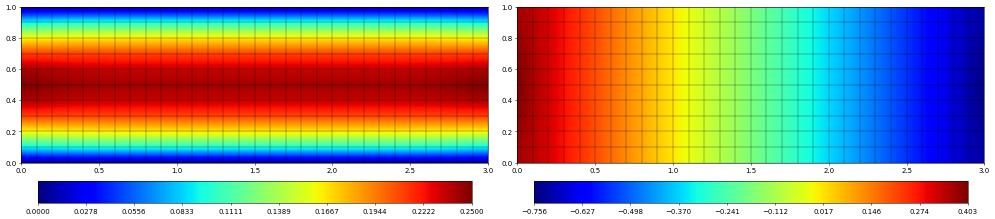

In [7]:
fig = pyplot.figure(figsize=(20,10))
velocity.plot(colorbar="horizontal", figure=(fig, 121))
pressure.plot(colorbar="horizontal", figure=(fig, 122))

## Task: implement a parallel version of the algorithm

It is probably a good idea to do this in a copy of this file and to
not append it here.